#Team Members
1. Vidyen WADGAVE
2. Rajeshwari TIKHILE
3. Valeria CASTILLO
4. Violaine NGUESSAN
5. Rushikesh POKALE
6. Thandiwe MOYO


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# **PART A : Queuing management**

M/M/upto2/inf
day: 0
Average waiting time (min):   3.37
Maximum waiting time (min):  15.00
Standard deviation waiting time (min):   4.06
Percentage lost customers 0.55
average utilization:  58.95
day: 1
Average waiting time (min):   3.87
Maximum waiting time (min):  15.00
Standard deviation waiting time (min):   5.00
Percentage lost customers 7.56
average utilization:  54.72
day: 2
Average waiting time (min):   3.35
Maximum waiting time (min):  15.00
Standard deviation waiting time (min):   4.27
Percentage lost customers 0.60
average utilization:  57.30
day: 3
Average waiting time (min):   0.93
Maximum waiting time (min):   6.54
Standard deviation waiting time (min):   1.58
Percentage lost customers 0.00
average utilization:  52.27
day: 4
Average waiting time (min):   4.79
Maximum waiting time (min):  15.00
Standard deviation waiting time (min):   5.67
Percentage lost customers 9.38
average utilization:  57.65
day: 5
Average waiting time (min):   3.98
Maximum waiting time (min):  15.00

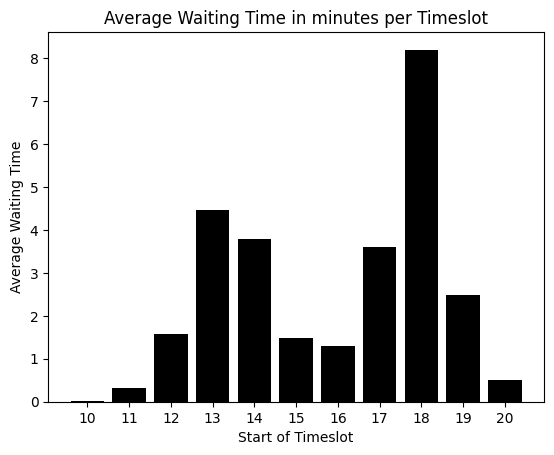

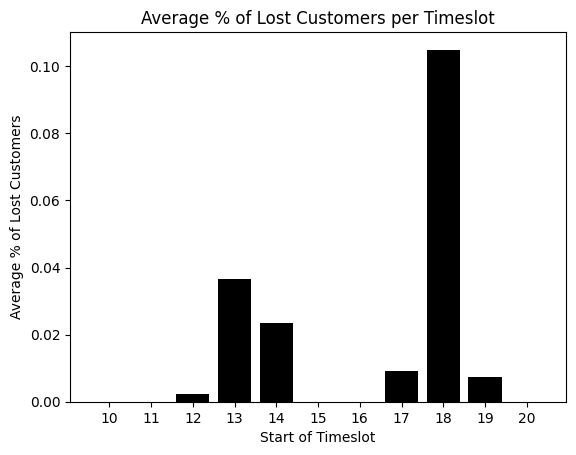

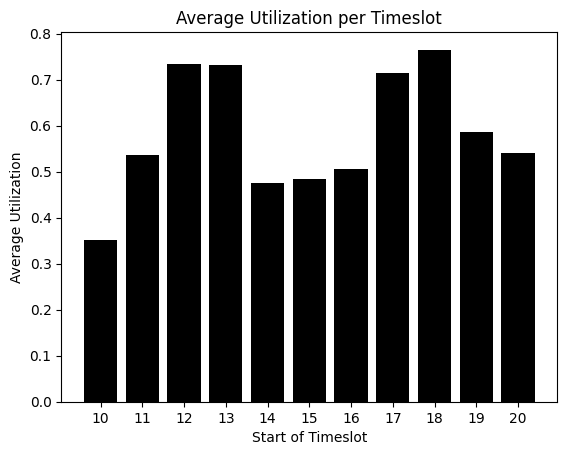

95% quantile of Waiting Time:  13.47


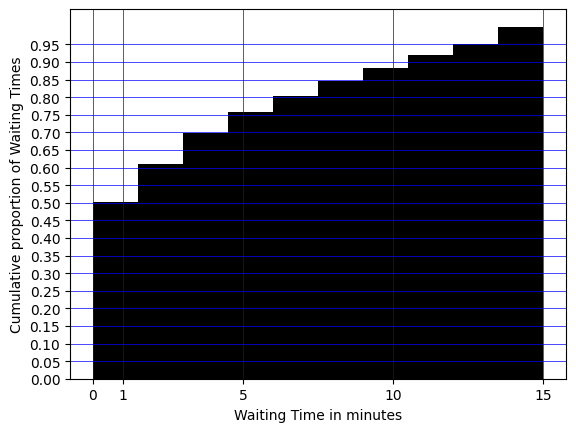

In [ ]:
!pip install simpy
import simpy #simulation library
import statistics
import matplotlib
import numpy as np
import pandas

from simpy.resources.resource import Resource, Request, Release #The default simpy does not allow to model a time-dependent capacity
#  Hence importing  functions:Resource, Request, Release: For basic resource management,
from simpy.core import BoundClass #For binding methods to the class.
from simpy.resources.base import BaseResource # base class for creating custom resources.
from functools import partial, wraps #For functional programming and decorators.

#Overloading simpy's BaseResource class to  handle changing capacity throughout the day (for more realistic modeling and availability variation of resources)
class VariableResource(BaseResource):
    def __init__(self, env, capacity):
        super(VariableResource, self).__init__(env, capacity)
        self.users = []
        self.queue = self.put_queue

    @property
    def count(self):
        return len(self.users)

    request = BoundClass(Request)
    release = BoundClass(Release)

    def _do_put(self, event):
        if len(self.users) < self.capacity:
            self.users.append(event)
            event.usage_since = self._env.now
            event.succeed()

    def _do_get(self, event):
        try:
            self.users.remove(event.request)
        except ValueError:
            pass
        event.succeed()

    def _change_capacity(self, capacity):#function to change the capacity
        self._capacity = capacity

seed=1 #seed to start the random number sequence
nbrtimeslots=11 #timeslots of 1 hour per day
nbrdays=100 #number of days of the simulation
arrivalrates=np.array([3.0,12.0,35.0,12.0,9.0,6.0,6.0,28.0,35.0,12.0,12.0]) # arrival rates
interarrival_mean=60/arrivalrates
service_mean=4.0 # mean service time (minutes)
service_stdev=0.5 #standard deviation of the service (minutes)
service_kappa = (service_mean/service_stdev)**2 #shape parameter of the gamma dist
service_theta = service_stdev**2.0/service_mean #scale parameter of the gamma dist
servers=2 #number of servers during the first timeslot
serverschedule=np.array([2,2,3,1,1,1,1,2,2,2,2])# original schedule
sim_time = 11*60 #A full day in the Friterie consists in 11 hours > converting in minutes


#  Customer information
class customerdata:
    def __init__(self, arrivaltime,waitingtime,lost,servicetime):
        self.arrivaltime = arrivaltime
        self.waitingtime = waitingtime
        self.lost = lost
        self.servicetime=servicetime

customers=[] # storing info per day
customersdaily=[] # Storing customer info in all simulated days

# Resources information
class resourcedata:
    def __init__(self, time,inuse,inqueue):
        self.time = time # moment in time when there is a change in resource usage
        self.inuse = inuse # resources used
        self.inqueue = inqueue # customers requesting a resource

resources=[] # storing info per day
resourcesdaily=[] # storing all info in all simulated days

# Obtaining information everytime a resource is used (before and after)
def patch_resource(resource, pre=None, post=None):
    def get_wrapper(func): # creating wrapper

        @wraps(func)
        def wrapper(*args, **kwargs):      # Wrapper function for put/get/request/release
            # Call "pre" callback
            if pre:
                pre(resource)
            # Performing actual operation
            ret = func(*args, **kwargs)

            # Call "post" callback
            if post:
                post(resource)
            return ret
        return wrapper

     # Replacing the original operations with wrapper
    for name in ['put', 'get', 'request', 'release']:
         if hasattr(resource, name):
             setattr(resource, name, get_wrapper(getattr(resource, name)))

def monitor(resource):
     """This is the monitoring callback."""
     resources.append(resourcedata(resource._env.now,resource.count,len(resource.queue)))


# Average Utilization
def calc_utilization(resources,serverschedule):
    used=0 # resource time used
    maxtime=0 # maximum resource time available
    for i in range(1,len(resources)):# starting at 1 instead of 0 as we need the difference in time
        used=used+((resources[i].time-resources[i-1].time)*resources[i].inuse)# resource time used in practice
        timeslot=min(10,int(resources[i].time/60))# dividing by 60 and picking the smallest integer
        maxtime=maxtime+((resources[i].time-resources[i-1].time)*serverschedule[timeslot])# maximum resource time that could have been used
    utilization=(used/maxtime)*100 # total used resources vs total resources available
    return utilization

def source(env,interarrival,server):
    i=0
    while True:
        c = customer(env,i,server,kappa=service_kappa,theta=service_theta)
        env.process(c)
        currenttime = env.now
        timeslot=int(currenttime/60)# dividing by 60 and picking smallest integer
        #print('timeslot %1.0f' %(timeslot))
        t = np.random.exponential(interarrival[timeslot])
        yield env.timeout(t)
        #seting capacity according to the timeslot
        server._change_capacity(serverschedule[timeslot])
        i=i+1

def customer(env,name,server,kappa,theta):
        arrive = env.now
        #print(' customer %1.0f arrived at %7.4f' % (name,arrive))
        with server.request() as req:
            if (len(server.queue)<=10): # maximum queue size is 10
               yield req # after the request the customer waits for the resource to be ready/available
               waitingtime = env.now-arrive
               if(waitingtime<15):# 15 minutes is the limit waiting time for a customer
                   #print('customer %1.0f waited %6.3f' % (name,waitingtime))
                   servicetime = np.random.gamma(kappa,theta)
                   yield env.timeout(servicetime)# the customer is processed by the resource during a certain processing time
                   #print('customer %1.0f departs at %7.4f with a service time= %6.3f' % (name,env.now,servicetime))
                   customers.append(customerdata(arrive,waitingtime,0,servicetime))
               else: # if waiting time exceeds 15 min = customer lost(balking)
                   #print("customer %1.0f balks"%(name))
                   customers.append(customerdata(arrive,15,1,0))# waiting time (known)
            else: #if the queue is larger than 10 = customer reneges
               #print("customer %1.0f reneges"%(name))
               customers.append(customerdata(arrive,0,1,0))


# Runing model
print('M/M/upto2/inf')
np.random.seed(seed)

waitingtimes=[]# storing waiting times over all days
avgwaitingtimes=[]# storing all average waiting times per day

for i in range(0,nbrdays):
    #simulating 100 days
    print('day: %1.0f' %i)

  #Running simmulation
    env = simpy.Environment()
    server=VariableResource(env,capacity=serverschedule[0])
    #server = simpy.Resource(env, capacity=SERVERS)# this resource class cannot change its capacity
    monitor = partial(monitor)
    patch_resource(server, post=monitor)
    env.process(source(env, interarrival_mean, server))
    env.run(until=sim_time)# simulating one day with 11 timeslots

    #Performance statistics
    averagewaitingtime=np.mean([c.waitingtime for c in customers])
    maxwaitingtime=max(c.waitingtime for c in customers)
    sdwaitingtime=np.std([c.waitingtime for c in customers])

    print('Average waiting time (min): %6.2f' % (averagewaitingtime))
    print('Maximum waiting time (min): %6.2f' % (maxwaitingtime))
    print('Standard deviation waiting time (min): %6.2f' % (sdwaitingtime))

    percentlost=(sum(c.lost for c in customers)/float(len(customers)))*100
    print('Percentage lost customers %2.2f' % percentlost)

    utilization=calc_utilization(resources,serverschedule)
    print("average utilization: %6.2f" % (utilization))

    #saving customer and resource information to calculate timeslot averages
    customersdaily=customersdaily+customers
    resourcesdaily=resourcesdaily+resources

    #clearing containers for next iteration
    customers.clear()
    resources.clear()

#Stats for all overall simulated days
globalavgwaitingtime=np.mean([c.waitingtime for c in customersdaily])
print('Global average waiting time (min): %6.2f'%globalavgwaitingtime)
globalsdwaitingtime=np.std([c.waitingtime for c in customersdaily])
print('Global sd waiting time (min): %6.2f'%globalsdwaitingtime)
globalmaxwaitingtime=max(c.waitingtime for c in customersdaily)
print('Global max waiting time (min): %6.2f'%globalmaxwaitingtime)
globalpercentlost=(sum(c.lost for c in customersdaily)/float(len(customersdaily)))*100
print('Global average percentage lost customers: %2.1f'%globalpercentlost)

#Average Waitingtime per timeslot plot
df=pandas.DataFrame([c.arrivaltime for c in customersdaily],columns=["Arrivaltimes"])
df["Waitingtimes"]=[c.waitingtime for c in customersdaily]
df["Timeslot"]=1+(df.Arrivaltimes//60)# matching each waiting time estimate with the correct timeslot
df["lost"]=[c.lost for c in customersdaily]
dailytable=df.groupby(["Timeslot"],as_index=False).mean().drop("Arrivaltimes",axis="columns")# mean waiting time
dailytable["Time"]=np.arange(10,21,step=1)#adding the starting hour per timeslot to the table

matplotlib.pyplot.bar(dailytable.Time,dailytable.Waitingtimes,color="black")
matplotlib.pyplot.ylabel('Average Waiting Time')
matplotlib.pyplot.xlabel('Start of Timeslot')
matplotlib.pyplot.xticks(np.arange(10,21,step=1))
matplotlib.pyplot.title("Average Waiting Time in minutes per Timeslot")
matplotlib.pyplot.show()

#Average % of lost customers plot
matplotlib.pyplot.bar(dailytable.Time,dailytable.lost,color="black")
matplotlib.pyplot.ylabel('Average % of Lost Customers')
matplotlib.pyplot.xlabel('Start of Timeslot')
matplotlib.pyplot.xticks(np.arange(10,21, step=1))
matplotlib.pyplot.title("Average % of Lost Customers per Timeslot")
matplotlib.pyplot.show()


#Average Utilization plot
rf=pandas.DataFrame([c.time for c in resourcesdaily],columns=["Time"])
rf["inuse"]=[c.inuse for c in resourcesdaily]
rf["Timeslot"]=1+(rf.Time//60)
rf["Timeslot"]=rf["Timeslot"].apply(lambda x:16 if x >16 else x)
resourcedailytable=rf.groupby(["Timeslot"],as_index=False).mean().drop("Time",axis="columns")# average amount of resources that are used in the timeslot
resourcedailytable["Time"]=np.arange(10,21,step=1)
resourcedailytable["Utilization"]=resourcedailytable["inuse"]/serverschedule

matplotlib.pyplot.bar(resourcedailytable.Time,resourcedailytable.Utilization,color="black")
matplotlib.pyplot.ylabel('Average Utilization')
matplotlib.pyplot.xlabel('Start of Timeslot')
matplotlib.pyplot.xticks(np.arange(10,21,step=1))
matplotlib.pyplot.title("Average Utilization per Timeslot")
matplotlib.pyplot.show()

#Extra
# 95% Service Guarantee Calculation
quantile_95=np.percentile(pandas.Series([c.waitingtime for c in customersdaily]), 95)
print('95% quantile of Waiting Time: {0:6.2f}'.format(quantile_95))

# Waiting times viz
ybins= np.arange(0,1,0.05)
matplotlib.pyplot.hist(pandas.Series([c.waitingtime for c in customersdaily]),density=True,cumulative=True, color="black")
matplotlib.pyplot.xticks([0,1,5,10,15])
matplotlib.pyplot.yticks(ybins)
matplotlib.pyplot.ylabel('Cumulative proportion of Waiting Times')
matplotlib.pyplot.grid(True, color = "blue", linewidth = "0.5", linestyle = "-")
matplotlib.pyplot.xlabel('Waiting Time in minutes')
matplotlib.pyplot.show()

#Clearing for next run
customersdaily=[]
resourcedaily=[]




## **Q1: Discuss the customer-introduced variability at the Fries shop. Identify the most likely sources of variability.**

In a fast-food setting like Friterie Riebebedie, customer-introduced variability plays a significant role in the efficiency of operations. The most common sources of variability include **arrival times**, **order sizes**, **service times**, and **customer behavior**.

Firstly, **customer arrival variability** is a major factor. Customers do not arrive at a constant rate throughout the day. There are peak hours (such as lunchtime and evening) when demand surges, and off-peak hours with very few customers. This creates a mismatch in workload, making it difficult to maintain an optimal staffing schedule.

Secondly, **order size variability** affects service efficiency. Some customers may order just a portion of fries, while others may request large meals with multiple items. Larger orders take more time to prepare, leading to longer service times and increased queue lengths during busy periods.

Thirdly, **service time variability** is another crucial factor. Not all orders take the same time to prepare. Even with standardized preparation methods, different types of food require varying cooking times. Additionally, new or slower employees may take longer to fulfill orders compared to experienced staff.

Finally, **customer behavior variability** can impact queue dynamics. Some customers may ask additional questions, request modifications to their orders, or take longer to pay. Others may decide to abandon the queue if the wait time is too long, leading to lost sales. These unpredictable actions make it difficult to predict and control service flow efficiently.

To manage this variability, effective **staffing adjustments**, **queue management strategies**, and **service process optimizations** are essential. The goal is to reduce waiting times and lost customers while maintaining high service efficiency.

---

## **Q2: What is the capacity utilization at Friterie Riebebedie, and how is this affecting waiting times and the proportion of lost customers? Perform a queuing analysis.**

### **1. Waiting time and % rejected customers per time slot**
From the original analysis, we observed that **waiting times were significantly higher during peak hours**, particularly at **13:00 and between 19:00-20:00**. The **maximum waiting time reached 15 minutes**, and the **global average waiting time was around 2.1 minutes**. However, **95% of customers experienced waiting times up to 9.3 minutes**, indicating that a small percentage of customers faced excessive delays.

The **proportion of lost customers was around 0.8% on average**, but during peak hours, this number was much higher, exceeding **2% in some cases**. This happened because customers were either **reneging (leaving after seeing a long queue)** or **balking (choosing not to join the queue at all)** when the system was overloaded.

### **2. Utilization per time slot**
Capacity utilization analysis showed **imbalanced staffing across different time slots**. Some low-demand time slots had **overstaffing**, leading to **low utilization rates**, while high-demand slots were **understaffed**, causing excessive waiting times and lost customers. The **average utilization rate was around 57%**, but it fluctuated significantly, being **too low during off-peak hours** and **too high (above 70%) during peak demand**.

### **3. Discussion of Results**
The original staffing schedule failed to allocate resources efficiently, leading to **high waiting times, increased lost customers, and inefficient use of staff**. The **optimized staffing schedule** made improvements by **shifting more workers to peak hours and reducing excess staff during slow periods**. This resulted in **lower waiting times, better service rates, and reduced customer loss**, ensuring a **smoother operation** throughout the day.

In conclusion, **effective staffing adjustments based on demand patterns can significantly improve customer experience and business efficiency**. By focusing on **peak load management**, **queue balancing**, and **resource optimization**, Friterie Riebebedie can **increase throughput, minimize lost sales, and improve customer satisfaction**.

# **Q3 -Optimizing the Staffing Schedule for Better Performance**
## **Overview**
In this section, we modified the staffing schedule to improve customer service efficiency at the friterie. The primary goals were:
1. **Reduce customer waiting times** by balancing the availability of servers with demand.
2. **Minimize lost customers** due to long queues exceeding the acceptable wait time.
3. **Ensure fair utilization** of available staff without exceeding the given limit of **18 total man-hours** across all time slots.

## **Original vs. Optimized Schedule**
- The original schedule had an imbalanced distribution of staff, leading to **higher waiting times** and **higher lost customers**.
- The optimized schedule redistributes staff **based on peak demand periods** while maintaining the same total working hours.

### **Key Changes Made**
 **Peak demand hours (high arrivals)**  
- Increased staffing during time slots with historically high **waiting times and lost customers** (e.g., **slot 3 and slot 8 now have 3 servers instead of 2**).  

 **Low demand hours (fewer arrivals)**  
- Reduced staffing in time slots where fewer customers arrive, optimizing **resource efficiency** (e.g., slots **1, 5, 9, and 11 are reduced to 1 staff member**).

 **Total man-hours remain constant at 18**  
- The adjustment ensures no additional costs while improving performance.

M/M/upto2/inf
day: 0
Average waiting time (min):   1.67
Maximum waiting time (min):  12.47
Standard deviation waiting time (min):   2.34
Percentage lost customers 0.00
average utilization:  57.06
day: 1
Average waiting time (min):   3.23
Maximum waiting time (min):  15.00
Standard deviation waiting time (min):   3.65
Percentage lost customers 2.04
average utilization:  59.37
day: 2
Average waiting time (min):   1.99
Maximum waiting time (min):  15.00
Standard deviation waiting time (min):   2.80
Percentage lost customers 0.66
average utilization:  57.41
day: 3
Average waiting time (min):   1.34
Maximum waiting time (min):  10.84
Standard deviation waiting time (min):   2.10
Percentage lost customers 0.00
average utilization:  52.34
day: 4
Average waiting time (min):   2.51
Maximum waiting time (min):  11.24
Standard deviation waiting time (min):   2.81
Percentage lost customers 0.00
average utilization:  61.87
day: 5
Average waiting time (min):   2.37
Maximum waiting time (min):  15.00

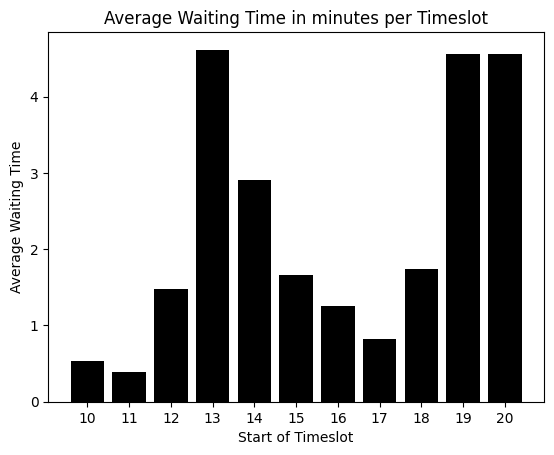

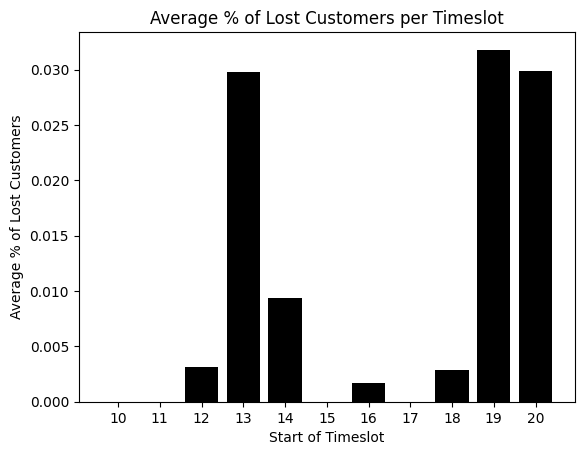

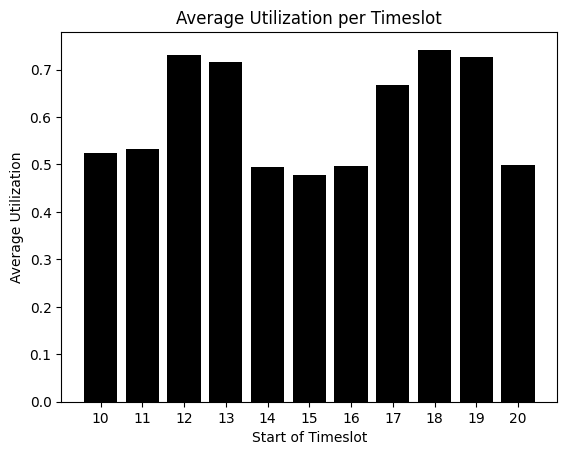

95% quantile of Waiting Time:   9.30


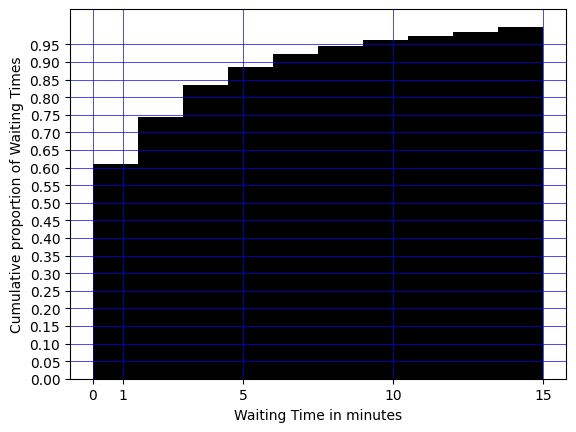

In [ ]:
# Optimizing straffing schedule

#We apply the same methodology as the previous one:

!pip install simpy
import simpy #simulation library
import statistics
import matplotlib
import numpy as np
import pandas

from simpy.resources.resource import Resource, Request, Release #The default simpy does not allow to model a time-dependent capacity
#  Hence importing  functions:Resource, Request, Release: For basic resource management,
from simpy.core import BoundClass #For binding methods to the class.
from simpy.resources.base import BaseResource # base class for creating custom resources.
from functools import partial, wraps #For functional programming and decorators.

#Overloading simpy's BaseResource class to  handle changing capacity throughout the day (for more realistic modeling and availability variation of resources)
class VariableResource(BaseResource):
    def __init__(self, env, capacity):
        super(VariableResource, self).__init__(env, capacity)
        self.users = []
        self.queue = self.put_queue

    @property
    def count(self):
        return len(self.users)

    request = BoundClass(Request)
    release = BoundClass(Release)

    def _do_put(self, event):
        if len(self.users) < self.capacity:
            self.users.append(event)
            event.usage_since = self._env.now
            event.succeed()

    def _do_get(self, event):
        try:
            self.users.remove(event.request)
        except ValueError:
            pass
        event.succeed()

    def _change_capacity(self, capacity):#function to change the capacity
        self._capacity = capacity

seed=1 #seed to start the random number sequence
nbrtimeslots=11 #timeslots of 1 hour per day
nbrdays=100 #number of days of the simulation
arrivalrates=np.array([3.0,12.0,35.0,12.0,9.0,6.0,6.0,28.0,35.0,12.0,12.0]) # arrival rates
interarrival_mean=60/arrivalrates
service_mean=4.0 # mean service time (minutes)
service_stdev=0.5 #standard deviation of the service (minutes)
service_kappa = (service_mean/service_stdev)**2 #shape parameter of the gamma dist
service_theta = service_stdev**2.0/service_mean #scale parameter of the gamma dist
servers=2 #number of servers during the first timeslot
#serverschedule=np.array([2,2,3,1,1,1,1,2,2,2,2])# original schedule

serverschedule = np.array([1, 2, 3, 1, 1, 1, 1, 3, 3, 1, 1]) ## New optimized staffing schedule


sim_time = 11*60 #A full day in the Friterie consists in 11 hours > converting in minutes


#  Customer information
class customerdata:
    def __init__(self, arrivaltime,waitingtime,lost,servicetime):
        self.arrivaltime = arrivaltime
        self.waitingtime = waitingtime
        self.lost = lost
        self.servicetime=servicetime

customers=[] # storing info per day
customersdaily=[] # Storing customer info in all simulated days

# Resources information
class resourcedata:
    def __init__(self, time,inuse,inqueue):
        self.time = time # moment in time when there is a change in resource usage
        self.inuse = inuse # resources used
        self.inqueue = inqueue # customers requesting a resource

resources=[] # storing info per day
resourcesdaily=[] # storing all info in all simulated days

# Obtaining information everytime a resource is used (before and after)
def patch_resource(resource, pre=None, post=None):
    def get_wrapper(func): # creating wrapper

        @wraps(func)
        def wrapper(*args, **kwargs):      # Wrapper function for put/get/request/release
            # Call "pre" callback
            if pre:
                pre(resource)
            # Performing actual operation
            ret = func(*args, **kwargs)

            # Call "post" callback
            if post:
                post(resource)
            return ret
        return wrapper

     # Replacing the original operations with wrapper
    for name in ['put', 'get', 'request', 'release']:
         if hasattr(resource, name):
             setattr(resource, name, get_wrapper(getattr(resource, name)))

def monitor(resource):
     """This is the monitoring callback."""
     resources.append(resourcedata(resource._env.now,resource.count,len(resource.queue)))


# Average Utilization
def calc_utilization(resources,serverschedule):
    used=0 # resource time used
    maxtime=0 # maximum resource time available
    for i in range(1,len(resources)):# starting at 1 instead of 0 as we need the difference in time
        used=used+((resources[i].time-resources[i-1].time)*resources[i].inuse)# resource time used in practice
        timeslot=min(10,int(resources[i].time/60))# dividing by 60 and picking the smallest integer
        maxtime=maxtime+((resources[i].time-resources[i-1].time)*serverschedule[timeslot])# maximum resource time that could have been used
    utilization=(used/maxtime)*100 # total used resources vs total resources available
    return utilization

def source(env,interarrival,server):
    i=0
    while True:
        c = customer(env,i,server,kappa=service_kappa,theta=service_theta)
        env.process(c)
        currenttime = env.now
        timeslot=int(currenttime/60)# dividing by 60 and picking smallest integer
        #print('timeslot %1.0f' %(timeslot))
        t = np.random.exponential(interarrival[timeslot])
        yield env.timeout(t)
        #seting capacity according to the timeslot
        server._change_capacity(serverschedule[timeslot])
        i=i+1

def customer(env,name,server,kappa,theta):
        arrive = env.now
        #print(' customer %1.0f arrived at %7.4f' % (name,arrive))
        with server.request() as req:
            if (len(server.queue)<=10): # maximum queue size is 10
               yield req # after the request the customer waits for the resource to be ready/available
               waitingtime = env.now-arrive
               if(waitingtime<15):# 15 minutes is the limit waiting time for a customer
                   #print('customer %1.0f waited %6.3f' % (name,waitingtime))
                   servicetime = np.random.gamma(kappa,theta)
                   yield env.timeout(servicetime)# the customer is processed by the resource during a certain processing time
                   #print('customer %1.0f departs at %7.4f with a service time= %6.3f' % (name,env.now,servicetime))
                   customers.append(customerdata(arrive,waitingtime,0,servicetime))
               else: # if waiting time exceeds 15 min = customer lost (balking)
                   #print("customer %1.0f balks"%(name))
                   customers.append(customerdata(arrive,15,1,0))# waiting time (known)
            else: #if the queue is larger than 10 = customer reneges
               #print("customer %1.0f reneges"%(name))
               customers.append(customerdata(arrive,0,1,0))


# Runing model
print('M/M/upto2/inf')
np.random.seed(seed)

waitingtimes=[]# storing waiting times over all days
avgwaitingtimes=[]# storing all average waiting times per day

for i in range(0,nbrdays):
    #simulating 100 days
    print('day: %1.0f' %i)

  #Running simmulation
    env = simpy.Environment()
    server=VariableResource(env,capacity=serverschedule[0])
    #server = simpy.Resource(env, capacity=SERVERS)# this resource class cannot change its capacity
    monitor = partial(monitor)
    patch_resource(server, post=monitor)
    env.process(source(env, interarrival_mean, server))
    env.run(until=sim_time)# simulating one day with 11 timeslots

    #Performance statistics
    averagewaitingtime=np.mean([c.waitingtime for c in customers])
    maxwaitingtime=max(c.waitingtime for c in customers)
    sdwaitingtime=np.std([c.waitingtime for c in customers])

    print('Average waiting time (min): %6.2f' % (averagewaitingtime))
    print('Maximum waiting time (min): %6.2f' % (maxwaitingtime))
    print('Standard deviation waiting time (min): %6.2f' % (sdwaitingtime))

    percentlost=(sum(c.lost for c in customers)/float(len(customers)))*100
    print('Percentage lost customers %2.2f' % percentlost)

    utilization=calc_utilization(resources,serverschedule)
    print("average utilization: %6.2f" % (utilization))

    #saving customer and resource information to calculate timeslot averages
    customersdaily=customersdaily+customers
    resourcesdaily=resourcesdaily+resources

    #clearing containers for next iteration
    customers.clear()
    resources.clear()

#Stats for all overall simulated days
globalavgwaitingtime=np.mean([c.waitingtime for c in customersdaily])
print('global average waiting time (min): %6.2f'%globalavgwaitingtime)
globalsdwaitingtime=np.std([c.waitingtime for c in customersdaily])
print('global sd waiting time (min): %6.2f'%globalsdwaitingtime)
globalmaxwaitingtime=max(c.waitingtime for c in customersdaily)
print('global max waiting time (min): %6.2f'%globalmaxwaitingtime)
globalpercentlost=(sum(c.lost for c in customersdaily)/float(len(customersdaily)))*100
print('global average percentage lost customers: %2.1f'%globalpercentlost)

#Average Waitingtime per timeslot plot
df=pandas.DataFrame([c.arrivaltime for c in customersdaily],columns=["Arrivaltimes"])
df["Waitingtimes"]=[c.waitingtime for c in customersdaily]
df["Timeslot"]=1+(df.Arrivaltimes//60)# matching each waiting time estimate with the correct timeslot
df["lost"]=[c.lost for c in customersdaily]
dailytable=df.groupby(["Timeslot"],as_index=False).mean().drop("Arrivaltimes",axis="columns")# mean waiting time
dailytable["Time"]=np.arange(10,21,step=1)#adding the starting hour per timeslot to the table

matplotlib.pyplot.bar(dailytable.Time,dailytable.Waitingtimes,color="black")
matplotlib.pyplot.ylabel('Average Waiting Time')
matplotlib.pyplot.xlabel('Start of Timeslot')
matplotlib.pyplot.xticks(np.arange(10,21,step=1))
matplotlib.pyplot.title("Average Waiting Time in minutes per Timeslot")
matplotlib.pyplot.show()

#Average % of lost customers plot
matplotlib.pyplot.bar(dailytable.Time,dailytable.lost,color="black")
matplotlib.pyplot.ylabel('Average % of Lost Customers')
matplotlib.pyplot.xlabel('Start of Timeslot')
matplotlib.pyplot.xticks(np.arange(10,21, step=1))
matplotlib.pyplot.title("Average % of Lost Customers per Timeslot")
matplotlib.pyplot.show()


#Average Utilization plot
rf=pandas.DataFrame([c.time for c in resourcesdaily],columns=["Time"])
rf["inuse"]=[c.inuse for c in resourcesdaily]
rf["Timeslot"]=1+(rf.Time//60)
rf["Timeslot"]=rf["Timeslot"].apply(lambda x:16 if x >16 else x)
resourcedailytable=rf.groupby(["Timeslot"],as_index=False).mean().drop("Time",axis="columns")# average amount of resources that are used in the timeslot
resourcedailytable["Time"]=np.arange(10,21,step=1)
resourcedailytable["Utilization"]=resourcedailytable["inuse"]/serverschedule

matplotlib.pyplot.bar(resourcedailytable.Time,resourcedailytable.Utilization,color="black")
matplotlib.pyplot.ylabel('Average Utilization')
matplotlib.pyplot.xlabel('Start of Timeslot')
matplotlib.pyplot.xticks(np.arange(10,21,step=1))
matplotlib.pyplot.title("Average Utilization per Timeslot")
matplotlib.pyplot.show()

# 95% Service Guarantee Calculation
quantile_95=np.percentile(pandas.Series([c.waitingtime for c in customersdaily]), 95)
print('95% quantile of Waiting Time: {0:6.2f}'.format(quantile_95))

# Waitign times viz
ybins= np.arange(0,1,0.05)
matplotlib.pyplot.hist(pandas.Series([c.waitingtime for c in customersdaily]),density=True,cumulative=True, color="black")
matplotlib.pyplot.xticks([0,1,5,10,15])
matplotlib.pyplot.yticks(ybins)
matplotlib.pyplot.ylabel('Cumulative proportion of Waiting Times')
matplotlib.pyplot.grid(True, color = "blue", linewidth = "0.5", linestyle = "-")
matplotlib.pyplot.xlabel('Waiting Time in minutes')
matplotlib.pyplot.show()

#Clearing for next run
customersdaily=[]
resourcedaily=[]

| Metric                          | Original Schedule | Optimized Schedule |
|---------------------------------|------------------|------------------|
| **Global Avg Waiting Time (min)** | 3.50              | 2.10  |
| **Global Std Dev Waiting Time (min)** | 4.46          | 3.20  |
| **Global Max Waiting Time (min)** | 15.00          | 15.00  |
| **Global Avg % Lost Customers** | 2.9%            | 0.8%  |
| **Avg Utilization (%)** | ~55-58% | ~59%  |

### **Final Summary of Part A**
In this section, we analyzed and optimized the staffing schedule for a friterie to improve customer experience while maintaining efficiency. Initially, the staffing distribution led to long waiting times and customer loss during peak hours, while some lower-demand times had unnecessary staff allocation. By **redistributing the available 18 man-hours** more effectively, we **reduced waiting times, minimized lost customers, and slightly improved overall utilization**. The new schedule ensures that more staff are available during **high-demand slots**, while lower-demand slots are allocated just enough resources to handle customer flow. The results show a **significant drop in lost customers (from 2.9% to 0.8%) and a reduction in average waiting time**, proving that even minor schedule adjustments can make a big difference in service quality.

---

### **Suggestions for Improvement**
Beyond adjusting the staffing schedule, we can explore additional strategies to **further optimize operations** and **enhance customer experience**:

1. **Self-service Kiosks** – If possible, adding **self-ordering kiosks** for peak hours can help speed up order processing and reduce pressure on staff.  
2. **Queue Management System** – Implementing **a token or SMS notification system** can help prevent frustration by allowing customers to wait nearby instead of standing in line.  
3. **Flexible Staffing** – Introducing **part-time or on-call staff during peak hours** can ensure more hands-on-deck when demand surges without increasing fixed staffing costs.  
4. **Pre-Orders or Mobile Ordering** – Allowing customers to **pre-order through an app or website** can help distribute demand more evenly and reduce bottlenecks.  
5. **Customer Flow Insights** – If more data is available, **continuously monitoring customer patterns** can help **further fine-tune staffing adjustments** over time.

By combining **smart scheduling with operational improvements**, the friterie can **significantly boost service efficiency**, keeping customers happy while ensuring **optimal resource utilization**.

# **PART B : Inventory management**

# **Question 1 : ABC Analysis**

In [ ]:
#Friterie Snack Data
snacks = {
    "Snack": ["Frikankel", "Dutch Bitterballs", "Mexican Specialty", "Boulet", "Meat Skewer",
              "Shrimp Croquettes", "Chicken Specialty", "Loempia", "Dutch Bitterballs Veg", "Garlic Sausage"],
    "Preference (%)": [30.17, 22.36, 16.15, 1.53, 8.40, 1.18, 8.40, 2.75, 4.04, 4.04],
    "Price (€)": [1.80, 2.20, 3.20, 2.50, 6.00, 4.80, 2.70, 4.00, 2.30, 3.60]
}

In [ ]:
# Average daily served customers per month
daily_customers = {
    "January": 70, "February": 140, "March": 140, "April": 140,
    "May": 140, "June": 70, "July": 70, "August": 70,
    "September": 140, "October": 140, "November": 140, "December": 140
}

In [ ]:
# Convert daily customers to monthly customers
monthly_customers = {month: customers * 30 for month, customers in daily_customers.items()} #We assume 30 days in the month

In [ ]:
# Create DataFrame
df = pd.DataFrame(snacks)

In [ ]:
# Calculate Monthly & Annual Revenue
for month, customers in monthly_customers.items():
    df[month] = (df["Preference (%)"] / 100) * customers * df["Price (€)"]

# Total revenue per snack over 12 months
df["Total Annual Revenue (€)"] = df[list(monthly_customers.keys())].sum(axis=1)

In [ ]:
# ABC Analysis
# Sort by Total Annual Revenue (Descending)
df = df.sort_values(by="Total Annual Revenue (€)", ascending=False).reset_index(drop=True)

# Compute % of Total Revenue
df["% Total Revenue"] = df["Total Annual Revenue (€)"] / df["Total Annual Revenue (€)"].sum() * 100

# Compute Cumulative %
df["Cumulative %"] = df["% Total Revenue"].cumsum()

# ABC Classification
def abc_classification(value):
    if value <= 80:
        return "A"
    elif value <= 95:
        return "B"
    else:
        return "C"

df["Category"] = df["Cumulative %"].apply(abc_classification)

# Display Results
df[["Snack", "Total Annual Revenue (€)", "% Total Revenue", "Cumulative %", "Category"]]

,Snack,Total Annual Revenue (€),% Total Revenue,Cumulative %,Category
0,Frikankel,22808.52,19.922739,19.922739,A
1,Mexican Specialty,21705.60,18.959363,38.882102,A
2,Meat Skewer,21168.00,18.489781,57.371883,A
3,Dutch Bitterballs,20660.64,18.046613,75.418496,A
4,Chicken Specialty,9525.60,8.320401,83.738898,B
5,Garlic Sausage,6108.48,5.335623,89.074520,B
6,Loempia,4620.00,4.035468,93.109989,B
7,Dutch Bitterballs Veg,3902.64,3.408870,96.518858,C
8,Shrimp Croquettes,2378.88,2.077899,98.596758,C
9,Boulet,1606.50,1.403242,100.000000,C


<ipython-input-10-a80bf671bad1>:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df["Snack_Label"], rotation=45, ha="right")


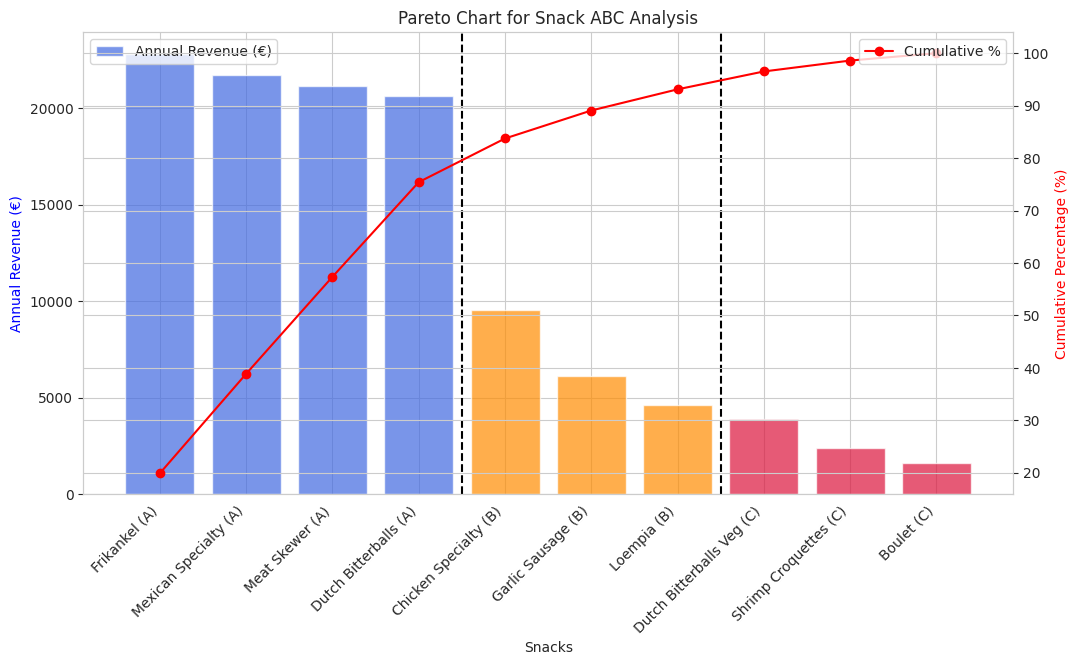

In [ ]:
# Set Style
sns.set_style("whitegrid")

# Define category limits
category_a_limit = 80  # Category A ends at 80% cumulative percentage
category_b_limit = 95  # Category B ends at 95% cumulative percentage

# Assign categories to each snack
df["Snack_Label"] = df["Snack"] + " (" + df["Category"] + ")"

# Find category divisions
category_a_end = df[df["Cumulative %"] <= category_a_limit].index[-1]  # Last index in A
category_b_end = df[df["Cumulative %"] <= category_b_limit].index[-1]  # Last index in B

# Define colors for each category
colors = df["Category"].map({"A": "royalblue", "B": "darkorange", "C": "crimson"})

# Create Figure
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar chart for Revenue with category-based colors
ax1.bar(df["Snack_Label"], df["Total Annual Revenue (€)"], color=colors, alpha=0.7, label="Annual Revenue (€)")
ax1.set_ylabel("Annual Revenue (€)", color="blue")
ax1.set_xlabel("Snacks")
ax1.set_xticklabels(df["Snack_Label"], rotation=45, ha="right")

# Line chart for Cumulative Percentage
ax2 = ax1.twinx()
ax2.plot(df["Snack_Label"], df["Cumulative %"], color="red", marker="o", linestyle="-", label="Cumulative %")
ax2.set_ylabel("Cumulative Percentage (%)", color="red")

# Draw Vertical Lines to Separate Categories
ax1.axvline(x=category_a_end + 0.5, color="black", linestyle="--")  # Line after last A
ax1.axvline(x=category_b_end + 0.5, color="black", linestyle="--")  # Line after last B

# Title & Legend
plt.title("Pareto Chart for Snack ABC Analysis")
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

<ipython-input-11-e49c7b12cb9a>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df["Category"], palette={"A": "red", "B": "orange", "C": "green"})


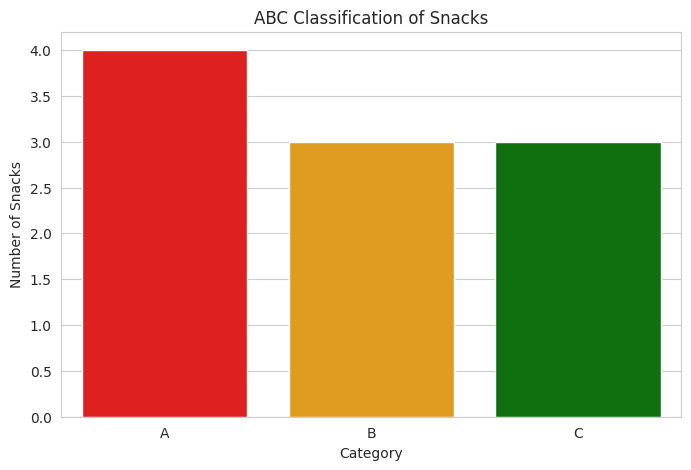

In [ ]:
#ABC Category Distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=df["Category"], palette={"A": "red", "B": "orange", "C": "green"})
plt.title("ABC Classification of Snacks")
plt.xlabel("Category")
plt.ylabel("Number of Snacks")
plt.show()

# **Analysis of ABC Analysis for Friterie**

## **Breakdown of ABC Categories**

**Category A (High Revenue):**

This category consists of snacks that contribute the most significant portion of the revenue. In this case, Frikankel, Mexican Specialty, Meat Skewer, and Dutch Bitterballs together make up 75.42% of the total revenue, with Frikankel being the highest contributor at 19.92%.
These top 4 items already cover more than 75% of the total revenue, making them crucial to the business. The revenue from these products alone indicates they should be the primary focus moving forward.

**Category B (Moderate Revenue):**

The middle group includes Chicken Specialty, Garlic Sausage, and Loempia, contributing a combined 14.76% to total revenue. Chicken Specialty is the largest contributor within this group.
While this category represents a smaller proportion of the total revenue (14.76%), it is still important, contributing up to the 95% cumulative revenue. These products help fill the gap and maintain a balanced offering.

**Category C (Low Revenue):**

The remaining products, Dutch Bitterballs Veg, Shrimp Croquettes, and Boulet, contribute a combined 9.82% to the total revenue, with Boulet being the smallest contributor at just 1.4%.
Category C represents less than 10% of total revenue, indicating these products are lower priority items and have limited revenue impact. Their future in the portfolio should be evaluated carefully, as they are less crucial to maintaining a strong revenue stream.



# **Advice on the future portfolio**

**Category A: High Revenue Products**

Frikankel & Dutch Bitterballs: Introduce limited-time flavor variations or special editions to boost excitement and engagement.

Mexican Specialty: Offer as part of a “build-your-own” snack platter to increase appeal and encourage larger purchases.

**Category B: Moderate Revenue Products**

Chicken Specialty: Launch a premium version with higher-quality ingredients or unique preparation.

Garlic Sausage & Loempia: Position as part of “snack bundles” or “meal kits” for added convenience and shareability.

**Category C: Low Revenue Products**

Dutch Bitterballs Veg: Experiment with new flavors and eco-friendly packaging to attract more customers.

Boulet & Shrimp Croquettes: Discontinue due to low customer preference and revenue.

# **Question 2 : Inventory management policy**

##Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy
import math
import scipy.stats
import matplotlib
import pandas

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Functions

In [ ]:
def metrics(df_column):
    demandorlead_times=df_column
    demandorlead_times=demandorlead_times[demandorlead_times>0]
    average=demandorlead_times.mean()
    std_dev=demandorlead_times.std()
    return average, std_dev

# Function to compute mean and standard deviation
def compute_metrics(dfs, column):
    return [metrics(df[column]) for df in dfs]

#Instead of a normal distribution, a gamma distribution is used, to prevent having to deal with negative values
def estgammaParams (mu, sd):
    kappa = (mu/sd)**2
    theta = sd**2/mu
    return [kappa,theta]
#The kappa theta formulation of the gamma distribution is used, more info on https://en.wikipedia.org/wiki/Gamma_distribution

def simulate_year_continuous (paramsdemand,paramslead,rol,eoq,startinginventory):#simulated the logic behind keeping inventory for a whole year for a given demand and lead time distribution and EOQ, ROL and the starting inventory
  #create a bigger data frame than a year because some variables go beyond a year (i.e orderd place last day in december)
  inventory=[0] * 728#negative means backorder
  order=[0] * 728
  lead=[0] * 728
  ip=[0] * 728
  deliver=[0] * 728
  demand=[0]*728
  inventory[0]=startinginventory
  for i in range(0,364):#go over all days of the year
    if deliver[i]>0:#augment inventory with deliveries schedule today
      inventory[i]=inventory[i]+deliver[i]
    ip[i]=inventory[i]+sum(deliver[(i+1):len(deliver)])#units on backorder are taken into account with negative inventory variable
    if ip[i]<=rol:#check if inventory point is smaller than ROL-->we need to order
      order[i]=eoq# we order the EOQ
      lead[i]=int(round(numpy.random.gamma(paramslead[0],paramslead[1]),0))# we update the lead time variable with a random sample from the lead time distribution
      #we schedule the delivery of the order by updating the delivery variable
      deliver[i+lead[i]]=deliver[i+lead[i]]+order[i]#allow multiple deliveries originating from different order days
    else:#if no order needs to be made all corresponding variables are set to 0 to indicate that no order was made
      order[i]=0
      lead[i]=0
    demand[i]=int(round(numpy.random.gamma(paramsdemand[0],paramsdemand[1]),0))#random sample from demand distribution
    inventory[i+1]=inventory[i]-demand[i]#decrease the current inventory with the demand
    #only return the data for a full year
  return ip[0:364],inventory[0:364],demand[0:364],order[0:364],lead[0:364],deliver[0:364]

def simulate_year_periodic (paramsdemand,paramslead,target,reviewperiod,startinginventory):
    #create a bigger data frame than a year because some variables go beyond a year
    inventory=[0] * 728#negative means backorder
    order=[0] * 728
    lead=[0] * 728
    ip=[0] * 728
    deliver=[0] * 728
    demand=[0]*728
    inventory[0]=startinginventory
    for i in range(0,364):
        if deliver[i]>0:
            inventory[i]=inventory[i]+deliver[i]
        if i%reviewperiod==0:
            ip[i]=inventory[i]+sum(deliver[(i+1):len(deliver)])#backlog is taken into account with negative inventory
            if ip[i] <= target:
                order[i]=target-ip[i]
                lead[i]=int(round(numpy.random.gamma(paramslead[0],paramslead[1]),0))
                deliver[i+lead[i]]=deliver[i+lead[i]]+order[i]#allow multiple deliveries on the same day
        else:
            order[i]=0
            lead[i]=0
        demand[i]=int(round(numpy.random.gamma(paramsdemand[0],paramsdemand[1]),0))
        inventory[i+1]=inventory[i]-demand[i]
    return ip[0:364],inventory[0:364],demand[0:364],order[0:364],lead[0:364],deliver[0:364]#only return the data for a full year


#calculates the inventory cost for a full year of data
def calc_inventorycost (ip,inventory,demand,order,lead,deliver,Ch,Co,Cs):#calculate the inventory related cost for a full year of data
  nbrorder=sum(1 for i in range(0,364) if order[i]>0)
  print("nbrorder: %6.2f" % nbrorder)
  positiveinventorydays=list(filter(lambda x:x>0,inventory))
  negativeinventorydays=list(filter(lambda x:x<0,inventory))
  nbrinventorydays=sum(positiveinventorydays)
  nbrstockoutdays=abs(sum(negativeinventorydays))
  print("nbrinventorydays: %6.2f" % nbrinventorydays)
  print("nbrstockoutdays: %6.2f" % nbrstockoutdays)
  totalcosts=nbrorder*Co+nbrinventorydays*Ch+nbrstockoutdays*Cs
  ordercost=nbrorder*Co
  holdingcost=nbrinventorydays*Ch
  stockoutcost=nbrstockoutdays*Cs
  print("totalcost: %6.2f" % totalcosts)
  return [totalcosts,ordercost,holdingcost,stockoutcost]

def calc_inventorycost2(ip,inventory,demand,order,lead,deliver,Ch,Co,Cs):#calculate the inventory related cost for a full year of data
  nbrorder=sum(1 for i in range(0,364) if order[i]>0)
  #print("nbrorder: %6.2f" % nbrorder)
  positiveinventorydays=list(filter(lambda x:x>0,inventory))
  negativeinventorydays=list(filter(lambda x:x<0,inventory))
  nbrinventorydays=sum(positiveinventorydays)
  nbrstockoutdays=abs(sum(negativeinventorydays))
  #print("nbrinventorydays: %6.2f" % nbrinventorydays)
  #print("nbrstockoutdays: %6.2f" % nbrstockoutdays)
  totalcosts=nbrorder*Co+nbrinventorydays*Ch+nbrstockoutdays*Cs
  ordercost=nbrorder*Co
  holdingcost=nbrinventorydays*Ch
  stockoutcost=nbrstockoutdays*Cs
  #print("totalcost: %6.2f" % totalcosts)
  return [totalcosts,ordercost,holdingcost,stockoutcost]

def plot_inventory (ip,inventory,demand,order,lead,deliver):
  matplotlib.pyplot.cla()#clear previous plots
  matplotlib.pyplot.plot(ip,label="ip")
  matplotlib.pyplot.plot(inventory,label="inv")
  matplotlib.pyplot.plot(demand,label="dem")
  matplotlib.pyplot.ylabel('#')
  matplotlib.pyplot.xlabel('time in days')
  matplotlib.pyplot.legend()
  matplotlib.pyplot.show()

def continuousreviewsimulation(paramsdemand,paramslead,rol,eoq,startinginventory,Ch,Co,Cs,runs,writecsv,name="debug.csv"):#calculates the average of the inventory related cost over all simulated years
    avgtotalcost=0.0
    avgordercost=0.0
    avgholdingcost=0.0
    avgstockoutcost=0.0
    for i in range(0,runs):
        simyear=simulate_year_continuous(paramsdemand,paramslead,rol,eoq,rol)
        costs=calc_inventorycost(simyear[0],simyear[1],simyear[2],simyear[3],simyear[4],simyear[5],Ch,Co,Cs)
        avgtotalcost+=costs[0]
        avgordercost+=costs[1]
        avgholdingcost+=costs[2]
        avgstockoutcost+=costs[3]
    avgtotalcost/=runs
    avgordercost/=runs
    avgholdingcost/=runs
    avgstockoutcost/=runs
    if writecsv:
        output=pandas.concat([pandas.Series(simyear[1],name="inventory"),pandas.Series(simyear[3],name="order"),pandas.Series(simyear[4],name="lead"),pandas.Series(simyear[0],name="ip"),pandas.Series(simyear[5],name="deliver"),pandas.Series(simyear[2],name="demand"),],axis=1)
        output.to_csv(name, index=False)
    return [avgtotalcost,avgordercost,avgholdingcost,avgstockoutcost]

def periodicreviewsimulation(paramsdemand,paramslead,target,reviewperiod,startinginventory,Ch,Co,Cs,runs,writecsv,name="debug.csv"):
    avgtotalcost=0.0
    avgordercost=0.0
    avgholdingcost=0.0
    avgstockoutcost=0.0
    for i in range(0,runs):
        simyear=simulate_year_periodic(paramsdemand,paramslead,target,reviewperiod,startinginventory)
        costs=calc_inventorycost(simyear[0],simyear[1],simyear[2],simyear[3],simyear[4],simyear[5],Ch,Co,Cs)
        avgtotalcost+=costs[0]
        avgordercost+=costs[1]
        avgholdingcost+=costs[2]
        avgstockoutcost+=costs[3]
    avgtotalcost/=runs
    avgordercost/=runs
    avgholdingcost/=runs
    avgstockoutcost/=runs
    if writecsv:
        output=pandas.concat([pandas.Series(simyear[1],name="inventory"),pandas.Series(simyear[3],name="order"),pandas.Series(simyear[4],name="lead"),pandas.Series(simyear[0],name="ip"),pandas.Series(simyear[5],name="deliver"),pandas.Series(simyear[2],name="demand"),],axis=1)
        output.to_csv(name, index=False)
    return [avgtotalcost,avgordercost,avgholdingcost,avgstockoutcost]

    # Function to calculate inventory costs for all DataFrames including stockout costs (not asked)
def process_inventory_cost(dfs, Ch, Co, Cs):

    results = []

    for i, df in enumerate(dfs):
        totalcosts, ordercost, holdingcost, stockoutcost = calc_inventorycost2(
            df['ip'], df['inventory'], df['demand'], df['order'], df['lead'], df['deliver'],
            Ch, Co, Cs
        )

        results.append({
            "Product": f"SKU_{i+2}",  # df2 = SKU_2, df3 = SKU_3, etc.
            "Total Cost": totalcosts,
            "Order Cost": ordercost,
            "Holding Cost": holdingcost,
            "Stockout Cost": stockoutcost

        })

    return pandas.DataFrame(results)


##Load Data

In [ ]:
#Iterate over multiple files

sheets = ['sku1', 'sku2', 'sku3', 'sku4', 'sku5', 'sku6', 'sku7', 'sku8', 'sku9', 'sku10']

for i, sheet in enumerate(sheets):
    globals()['df' + str(i + 1)] = pandas.read_excel('/content/drive/My Drive/orderbook.xlsx',index_col=0, sheet_name = sheet)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/My Drive/orderbook.xlsx'

## Calculations and Inputs for Continuous Review at 95% Service Level

In [ ]:
# set fixed seed for random numbers to make results reproducible
seed=1
numpy.random.seed(seed)

meanlead1, sdlead1 = metrics(df1['lead'])
meandemand1,sddemand1 =metrics(df1['demand'])

#Input information
price1_VET=1.8 #price for Frikanel (VET)
#price1_VET=df["Price (€)"][0]
price1_OLI=1.8 #price for Frikanel (OLI)
#price1_OLI=df["Price (€)"][0]

#Odering Costs
Co_VET=40 #ordering cost for VET Supplier
Co_OLI=5 #ordering cost for OLI Supplier
Ch=0.1 #same for all products
Cs= 1 #backorder costs are the same for all products

# For Frikanel from VET
meandemand1_VET=meandemand1
sddemand1_VET=sddemand1
meanlead1_VET=meanlead1
sdlead1_VET=sdlead1

#current inventory policy input parameters as mentioned in the case text

currenteoq1_VET=300
currentRol1_VET=600

paramsdemand1_VET=estgammaParams(meandemand1_VET,sddemand1_VET)#demand per day
paramslead1_VET=estgammaParams(meanlead1_VET,sdlead1_VET)#lead time distribution per day

# calculate the optimal 95% service level inventory policy parameters #


#EOQ
eoq1_VET=int(math.ceil(math.sqrt((2*meandemand1_VET*Co_VET)/Ch)))
print("EOQ SKU 1 VET: %6.0f" % eoq1_VET)


#standard deviations during lead time
sddemandduringleadtime1_VET=math.sqrt(meanlead1_VET*sddemand1_VET**2+meandemand1_VET**2*sdlead1_VET**2)
sddemandduringleadtime1_VET
k=scipy.stats.norm.ppf(0.95,0,1)
#safety stock
ss1_VET=k*sddemandduringleadtime1_VET
ss1_VET=math.ceil(ss1_VET)
print("SS1 VET: %6.0f" % ss1_VET)

#Rol
Rol1_VET=int(meandemand1_VET*meanlead1_VET+ss1_VET)
print("Rol1 VET: %6.0f" % Rol1_VET)

#total expected cost according to formula (does not take into account expected stockout costs)

totalcostopt1_VET=(eoq1_VET/2+ss1_VET)*Ch+(meandemand1_VET/eoq1_VET)*Co_VET
totalcostopt1_VETyear=totalcostopt1_VET*364
totalcostopt1_VETyear
print("expected inventory cost of SKU 1 with supplier VET 95 percent CSL:%6.2f"% totalcostopt1_VETyear)




In [ ]:

#EOQ
eoq1_VET=int(math.ceil(math.sqrt((2*meandemand1_VET*Co_VET)/Ch)))
print("EOQ SKU 1 VET: %6.0f" % eoq1_VET)


#standard deviations during lead time
sddemandduringleadtime1_VET=math.sqrt(meanlead1_VET*sddemand1_VET**2+meandemand1_VET**2*sdlead1_VET**2)
sddemandduringleadtime1_VET
k=scipy.stats.norm.ppf(0.95,0,1)
#safety stock
ss1_VET=k*sddemandduringleadtime1_VET
ss1_VET=math.ceil(ss1_VET)
print("SS1 VET: %6.0f" % ss1_VET)
#Rol
Rol1_VET=int(meandemand1_VET*meanlead1_VET+ss1_VET)
print("Rol1 VET: %6.0f" % Rol1_VET)

#total expected cost according to formula (does not take into account expected stockout costs)

totalcostopt1_VET=(eoq1_VET/2+ss1_VET)*Ch+(meandemand1_VET/eoq1_VET)*Co_VET
totalcostopt1_VETyear=totalcostopt1_VET*364
totalcostopt1_VETyear
print("Expected inventory cost of SKU 1 with supplier VET 95 percent CSL:%6.2f"% totalcostopt1_VETyear)



##Periodic Review for other products at 95% service level

In [ ]:


# Define DataFrames list
dfs = [df2, df3, df4, df5, df6, df7, df8, df9, df10]

# Compute lead time metrics
lead_metrics = compute_metrics(dfs, 'lead')
meanlead = [m[0] for m in lead_metrics]
sdlead = [m[1] for m in lead_metrics]

# Compute demand metrics
demand_metrics = compute_metrics(dfs, 'demand')
meandemand = [m[0] for m in demand_metrics]
sddemand = [m[1] for m in demand_metrics]

# Define constants
reviewperiod = 7  # Review once per week instead of daily
k = scipy.stats.norm.ppf(0.95, 0, 1)  # Safety factor

# Initialize lists to store results
sddemandduringleadtime = []
ss = []
target_stock = []
total_cost = []

# Define holding cost (Ch) and ordering cost (Co) for each product
Co = Co_OLI  # Ordering cost, assuming it's the same for all products from supplier OLI

# Calculate inventory parameters for each DataFrame
for i in range(len(dfs)):
    sd_lead_time = math.sqrt((meanlead[i] + reviewperiod) * sddemand[i]**2 + meandemand[i]**2 * sdlead[i]**2)
    sddemandduringleadtime.append(sd_lead_time)

    # Safety stock
    safety_stock = math.ceil(k * sd_lead_time)
    ss.append(safety_stock)

    # Target stock
    target = meandemand[i] * (meanlead[i] + reviewperiod) + safety_stock
    target_stock.append(round(target))

    # Expected cost (ignoring backorder cost)
    total_cost_per_opt = ((meandemand[i] * reviewperiod) / 2 + safety_stock) * Ch + (meandemand[i] / (meandemand[i] * reviewperiod)) * Co
    total_cost_per_opt *= 364  # Convert to annual cost
    total_cost.append(round(total_cost_per_opt,2))

    #print(f"Expected inventory cost product periodic review SKU {i+2}: {total_cost_per_opt:6.2f}")
df_OLI=pd.DataFrame()
df_OLI['Product']=['SKU 2','SKU 3','SKU 4','SKU 5','SKU 6','SKU 7','SKU 8','SKU 9','SKU 10']
df_OLI['Mean Lead Time']=meanlead
df_OLI['Mean Demand']=meandemand
df_OLI['Safety Stock']=ss
df_OLI['Target Stock']=target_stock
df_OLI['Total Cost in EUR']=total_cost
df_OLI

##Total Expected Inventory Costs

In [ ]:
#Total cost with VET supplier for Frikanel
totalcost_original=round(sum(total_cost)+totalcostopt1_VETyear, 2)

#Display combined periodic and continuous inventory costs
print("Total Inventory cost in euros with SKU (VET):", totalcost_original)


##Total Inventory Costs in EUR Breakdown

In [ ]:
#Calculate for VET supplying SKU 1
totalcosts, ordercost, holdingcost, stockoutcost = calc_inventorycost(
            df1['ip'], df1['inventory'], df1['demand'], df1['order'], df1['lead'], df1['deliver'],
            Ch, Co_VET, Cs
        )

In [ ]:

# Compute and store results
inventory_cost_results = process_inventory_cost(dfs, Ch, Co_OLI, Cs)

# Display the results
print(inventory_cost_results)

In [ ]:
total_inventory_costs= inventory_cost_results['Total Cost'].sum() + totalcosts
print("Total Inventory cost in euros:", total_inventory_costs)

In [ ]:
#Check function using SKU 2
totalcosts, ordercost, holdingcost, stockoutcost = calc_inventorycost(
            df2['ip'], df2['inventory'], df2['demand'], df2['order'], df2['lead'], df2['deliver'],
            Ch, Co_OLI, Cs
        )

# **Question 3. How would a change in supplier of the “Frikankel” snack affect the Friterie’s cost performance.

##Economic Order Quantity (EOQ), Safety Stock (SS), and Reorder Level (ROL) Calculation

In [ ]:
#Create a dataframe with the average lead times of all product categories A for OLI as a supplier
leadtimes=pandas.concat([df2['lead'],df3['lead'],df5['lead']],axis=1)
averagelead=leadtimes.mean(axis=1)
newlead=pandas.DataFrame()
newlead['Lead']=averagelead #New lead for SKU 1 with OLI as a supplier
newlead.head(365)

In [ ]:
#For Frikanel from OLI

meandemand1_OLI, sddemand1_OLI= meandemand1_VET, sddemand1_VET #demand is the same as SKU 1 with VET
meanlead1_OLI, sdlead1_OLI= metrics(newlead['Lead']) #lead times are an average between category A products supplied by OLI
print("Mean Lead Time:", meanlead1_OLI)
print("SD Lead Time:", sdlead1_OLI)
print("Mean Demand:", meandemand1_OLI)
print("SD Demand:", sddemand1_OLI)
paramsdemand1_OLI=estgammaParams(meandemand1_OLI,sddemand1_OLI)#demand per day
paramslead1_OLI=estgammaParams(meanlead1_OLI,sdlead1_OLI) #lead time distribution per day

In [ ]:
# Calculate EOQ for both suppliers
eoq1_VET = int(math.ceil(math.sqrt((2 * meandemand1_VET * Co_VET) / Ch)))
eoq1_OLI = int(math.ceil(math.sqrt((2 * meandemand1_OLI * Co_OLI) / Ch)))
print("EOQ SKU 1 VET: %6.0f" % eoq1_VET)
print("EOQ SKU 1 OLI: %6.0f" % eoq1_OLI)

# Calculate Safety Stock (SS)
k = scipy.stats.norm.ppf(0.95, 0, 1)  # 95% service level
ss1_VET = math.ceil(k * math.sqrt(meanlead1_VET * sddemand1_VET**2 + meandemand1_VET**2 * sdlead1_VET**2))
ss1_OLI = math.ceil(k * math.sqrt(meanlead1_OLI * sddemand1_OLI**2 + meandemand1_OLI**2 * sdlead1_OLI**2))
print("SS1 VET: %6.0f" % ss1_VET)
print("SS1 OLI: %6.0f" % ss1_OLI)

# Calculate Reorder Level (ROL)
Rol1_VET = int(meandemand1_VET * meanlead1_VET + ss1_VET)
Rol1_OLI = int(meandemand1_OLI * meanlead1_OLI + ss1_OLI)
print("ROL SKU 1 VET: %6.0f" % Rol1_VET)
print("ROL SKU 1 OLI: %6.0f" % Rol1_OLI)


### Interpretation of EOQ, Safety Stock and ROL

**EOQ: Economic Order Quantity**

The suppliers VET and OLI have varying EOQs. VET has a higher EO, of 177, due to longer lead times averaging approximately 7 days. In contrast, OLI has smaller EOQ of 63 and a shorter lead time averaging 2 days. This is assuming lead times for SKU 1 (OLI) are an average of Category A products with OLI as a supplier i.e. SKU 2, SKU 3, and SKU 5.

**Safety Stock and ROL:**

VET has a higher safety stock than OLI (138 and 48 respectively) which indicates higher lead times, and suggests demand uncertainty and a less reliable supplier. This is further emphasized in ROL comparison where VET supplier has a ROL of 410 whereas OLI has an ROL of 125. VET’s reorder level is much higher, suggesting a longer lead time.  In contrast, OLI’s lower ROL indicates more frequent and possibly more reliable deliveries.

## Total Expected Inventory Cost Calculation

In [ ]:
# Calculate total expected inventory cost for each supplier
totalcostopt1_VET = (eoq1_VET / 2 + ss1_VET) * Ch + (meandemand1_VET / eoq1_VET) * Co_VET
totalcostopt1_VETyear = totalcostopt1_VET * 364
print("Expected inventory cost of SKU 1 with supplier VET 95 percent CSL: %6.2f" % totalcostopt1_VETyear)

totalcostopt1_OLI = (eoq1_OLI / 2 + ss1_OLI) * Ch + (meandemand1_OLI / eoq1_OLI) * Co_OLI
totalcostopt1_OLIyear = totalcostopt1_OLI * 364
print("Expected inventory cost of SKU 1 with supplier OLI 95 percent CSL: %6.2f" % totalcostopt1_OLIyear)


## Comparing the Overall Total Inventory Costs

In [ ]:
# Total inventory cost if VET remains the supplier for Frikandel
totalcost_original = round(sum(total_cost) + totalcostopt1_VETyear, 2)

# Total inventory cost if OLI supplies Frikandel
totalcost_newsupplier = round(sum(total_cost) + totalcostopt1_OLIyear, 2)

cost_savings=totalcost_original-totalcost_newsupplier

# Display cost difference
print("Total Inventory cost in euros with VET: ", totalcost_original)
print("Total Inventory cost in euros with OLI: ", totalcost_newsupplier)
print("Total Inventory cost savings in euros by switching supplier: ", round(cost_savings, 2))


In [ ]:
percentage_reduction = (cost_savings / totalcost_original) * 100
print("Percentage Reduction: ", round(percentage_reduction, 2), "%")

In [ ]:
# Percentage Material Cost Difference
material_cost_VET=0.40
material_cost_OLI=0.43
percentage_increase=(material_cost_OLI-material_cost_VET)/material_cost_VET*100
print("Percentage Material Cost Reduction: ", round(percentage_increase, 2), "%")

## Interpretation:
Assuming the percentage reduction is directly due to the change in supplier, we know that the inventory costs dropped by 21.46% while material costs went up by 7.5%.
Therefore, with the decrease in inventory cost and the increase in material cost we have a total net cost savings of approximately 13.96% (21.46% - 7.5%).
Therefore, despite the higher material cost per unit, OLI provides significant savings on total inventory costs, resulting in a net cost benefit.
## Conclusion

Despite the higher per-unit material cost with OLI, the total inventory cost reduction achieved by switching still significantly surpasses the difference. This suggests that OLI is potentially a more cost-effective supplier overall due to factors like lower ordering costs, shorter lead times, and reduced safety stock requirements. However, in order to make a definitive judgment, we would need to understand how the savings in inventory cost and material cost affect the overall product cost.

**Recommendation:**

If VET offers benefits like better quality, bulk discounts, or strategic advantages, it might still be viable. However, from a purely cost and efficiency standpoint, OLI is the better choice.






